# Chapter 11 - Synthetic Controls

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#11.2.3-Synthetic-Synthetic-Control-Data" data-toc-modified-id="11.2.3-Synthetic-Synthetic-Control-Data-1">11.2.3 Synthetic Synthetic Control Data</a></span></li><li><span><a href="#11.2.5-OLS-Weights-in-Python" data-toc-modified-id="11.2.5-OLS-Weights-in-Python-2">11.2.5 OLS Weights in Python</a></span></li><li><span><a href="#11.2.6-A-“Wide”-Data-Problem" data-toc-modified-id="11.2.6-A-“Wide”-Data-Problem-3">11.2.6 A “Wide” Data Problem</a></span></li><li><span><a href="#11.3.1-Restricting-Weights" data-toc-modified-id="11.3.1-Restricting-Weights-4">11.3.1 Restricting Weights</a></span></li><li><span><a href="#11.3.2-Synthetic-Control-Estimator-in-Python" data-toc-modified-id="11.3.2-Synthetic-Control-Estimator-in-Python-5">11.3.2 Synthetic Control Estimator in Python</a></span></li><li><span><a href="#11.4.3-LASSO-in-Python" data-toc-modified-id="11.4.3-LASSO-in-Python-6">11.4.3 LASSO in Python</a></span></li><li><span><a href="#11.5.2-Convex-Matrix-Factorization" data-toc-modified-id="11.5.2-Convex-Matrix-Factorization-7">11.5.2 Convex Matrix Factorization</a></span></li><li><span><a href="#11.5.5-Convex-Factor-Model-Estimator-in-Python" data-toc-modified-id="11.5.5-Convex-Factor-Model-Estimator-in-Python-8">11.5.5 Convex Factor Model Estimator in Python</a></span></li><li><span><a href="#11.6.1-NLSY97-Data" data-toc-modified-id="11.6.1-NLSY97-Data-9">11.6.1 NLSY97 Data</a></span></li><li><span><a href="#11.6.2-Synthetic-Control-Estimates-of-the-Minimum-Wage-Effect" data-toc-modified-id="11.6.2-Synthetic-Control-Estimates-of-the-Minimum-Wage-Effect-10">11.6.2 Synthetic Control Estimates of the Minimum Wage Effect</a></span></li><li><span><a href="#11.6.3-LASSO-Estimates-of-the-Minimum-Wage-Effect" data-toc-modified-id="11.6.3-LASSO-Estimates-of-the-Minimum-Wage-Effect-11">11.6.3 LASSO Estimates of the Minimum Wage Effect</a></span></li><li><span><a href="#11.6.4-Factor-Model-Estimates-of-the-Minimum-Wage-Effect" data-toc-modified-id="11.6.4-Factor-Model-Estimates-of-the-Minimum-Wage-Effect-12">11.6.4 Factor Model Estimates of the Minimum Wage Effect</a></span></li></ul></div>

## 11.2.3 Synthetic Synthetic Control Data

In [1]:
# as in the other chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 200  # individuals
T = 35  # time periods
K = 3  # factors
sig = 0.1  # noise

# factors: a matrix with T rows and K columns
F = 3*np.random.rand(T, K)

# weights are positive
# a matrix with K rows and N columns, one column for each individual
Lambda = np.exp(np.random.normal(size=(K, N)))

# sum weights to 1
# .sum(axis=0) is the sum of each column: the three weights of one individual
Lambda = Lambda/Lambda.sum(axis=0)

# unobserved
E = np.random.normal(loc=0, scale=sig, size=(T, N))

Ybar = F.dot(Lambda)  # average outcome
Ys = Ybar + E  # actual outcome
# there is no policy effect in the simulated data

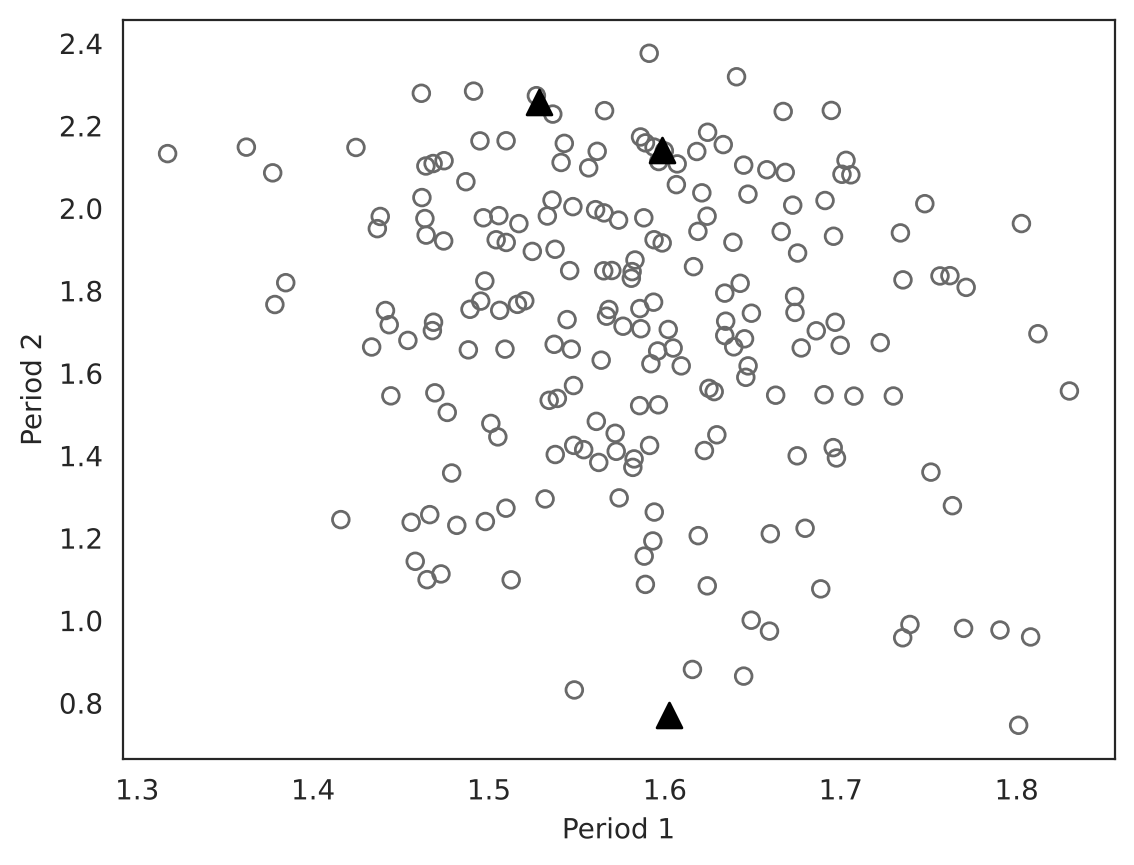

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking style, as in chapter 1
sns.set_style('white')

# outcomes of the 200 individuals in periods 1 and 2
# python starts counting at 0, so period 1 is row 0
plt.scatter(Ys[0, :], Ys[1, :], facecolors='none', color='dimgray')

# the triangles are the three factor values in the two periods
plt.scatter(F[0, :], F[1, :], marker='^', color='k', s=80)

plt.xlabel('Period 1')
plt.ylabel('Period 2')
plt.show()

## 11.2.5 OLS Weights in Python

In [5]:
# using statsmodels, as in the other chapters
import statsmodels.formula.api as sm

# the first 30 periods are used to estimate the weights
# individual 1 is column 0, individuals 2 to 5 are columns 1 to 4
# (python starts counting at 0, and 1:5 stops at column 4)
# X is a matrix: statsmodels makes one explanatory variable for each column
data = {'y': Ys[0:30, 0], 'X': Ys[0:30, 1:5]}
lm1 = sm.ols(formula="y ~ X", data=data).fit()
omega_hat = np.array(lm1.params)

# predicted outcomes of individual 1 in the last 5 periods
# np.c_ adds the column of 1's for the intercept (cbind in R)
y1_hat_ols = np.c_[np.ones(5), Ys[30:35, 1:5]].dot(omega_hat)

In [6]:
# the intercept and the weights on individuals 2 to 5
lm1.params

Intercept   -0.090762
X[0]        -0.738100
X[1]         0.811848
X[2]         1.241552
X[3]        -0.261994
dtype: float64

## 11.2.6 A “Wide” Data Problem

In [7]:
import pandas as pd

# create an empty list to fill with the results
rows = []

for i in range(2, 30):

    # same regression, with individuals 2 to i
    data = {'y': Ys[0:30, 0], 'X': Ys[0:30, 1:i]}
    lm1 = sm.ols(formula="y ~ X", data=data).fit()
    omega_hat = np.array(lm1.params)
    # prediction errors in the last 5 periods
    res = Ys[30:35, 0] - np.c_[np.ones(5), Ys[30:35, 1:i]].dot(omega_hat)
    # store i and the root mean squared error
    rows.append([i, np.mean(res**2)**0.5])

# creates a table of the rmse for different numbers of
# explanatory variables.
tab_res = pd.DataFrame(rows, columns=['i', 'rmse'])

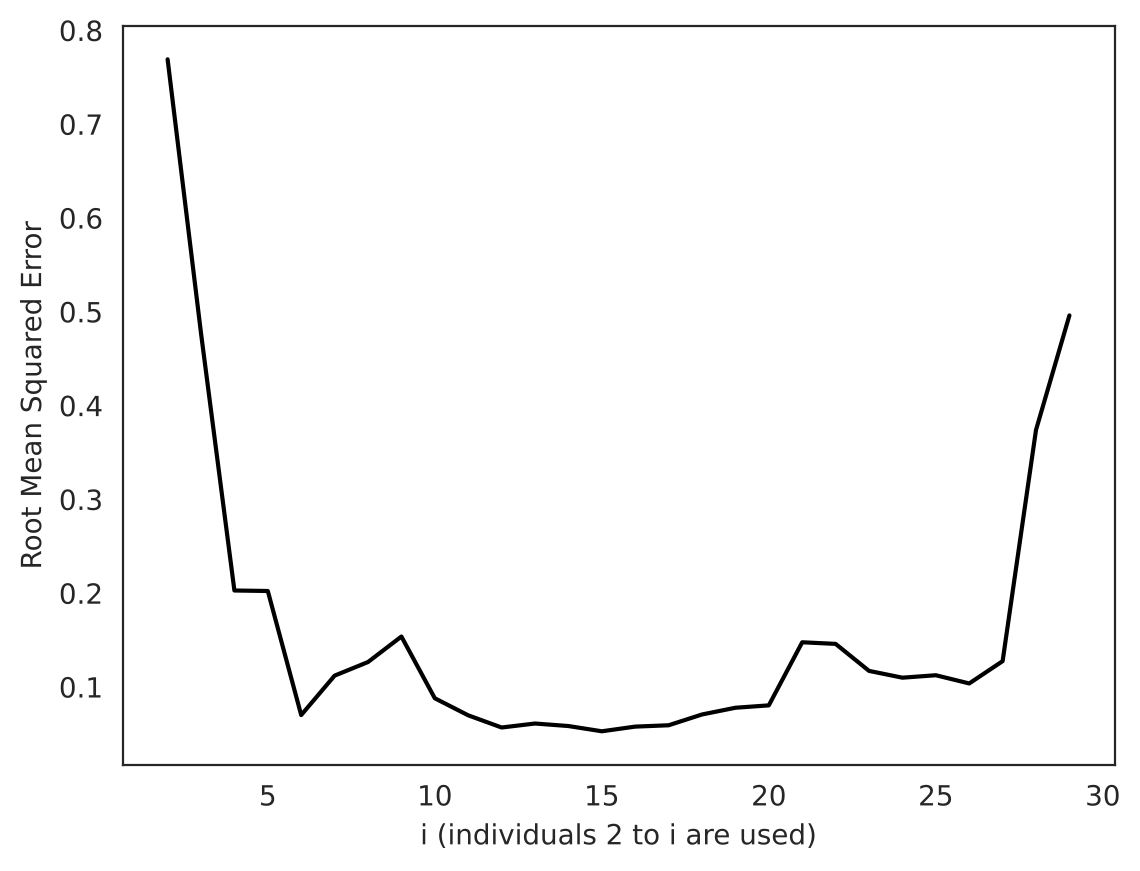

In [8]:
plt.plot(tab_res['i'], tab_res['rmse'], color='k')
plt.xlabel('i (individuals 2 to i are used)')
plt.ylabel('Root Mean Squared Error')
plt.show()

In [9]:
y1 = Ys[0:30, 0]
# all the individuals but individual 1
Y_n1 = Ys[0:30, 1:]

# the regression below is hashed out, as in the book
# with 199 individuals and 30 periods the matrix has no inverse
# R stops with an error
# inv() of numpy can give numbers with no error, but they mean nothing
#from numpy.linalg import inv
#omega_hat = inv(Y_n1.T.dot(Y_n1)).dot(Y_n1.T).dot(y1)

## 11.3.1 Restricting Weights

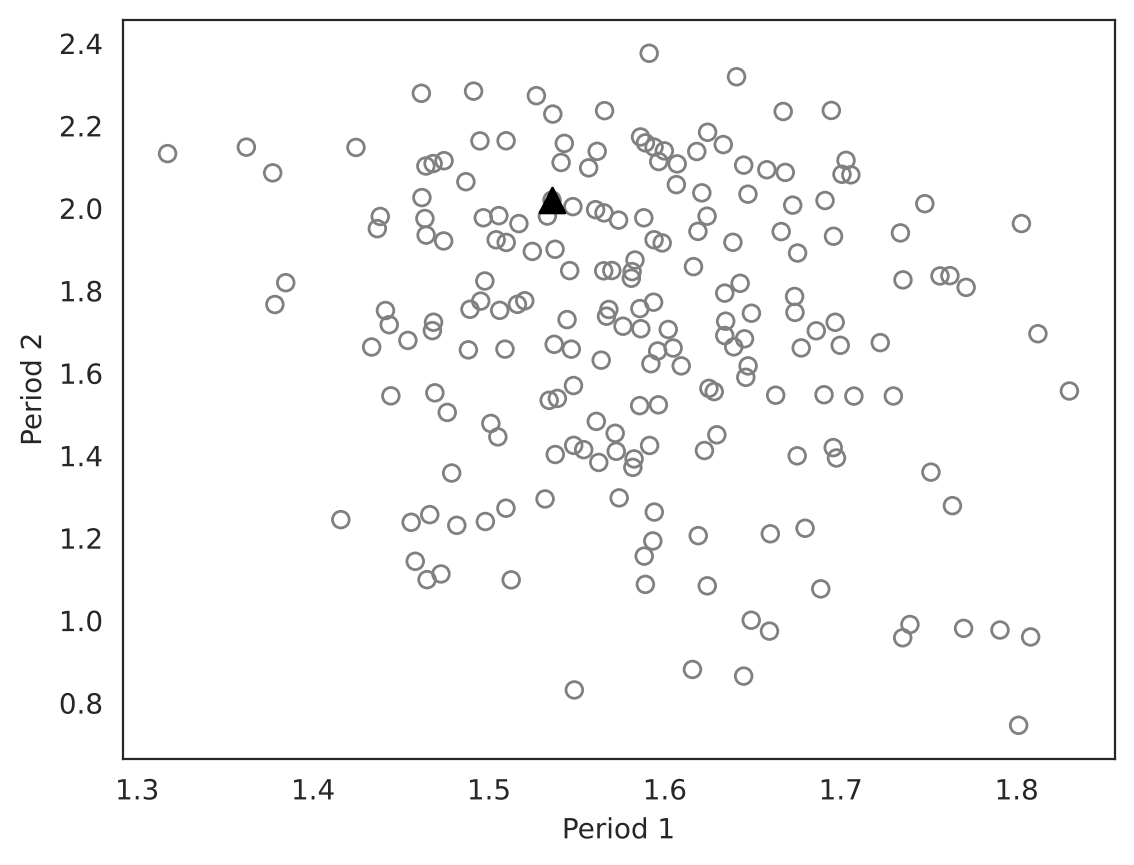

In [10]:
# simulated outcomes for period 1 and period 2
plt.scatter(Ys[0, :], Ys[1, :], facecolors='none', color='grey')

# the triangle is individual 1
plt.scatter(Ys[0, 0], Ys[1, 0], marker='^', color='k', s=80)

plt.xlabel('Period 1')
plt.ylabel('Period 2')
plt.show()

## 11.3.2 Synthetic Control Estimator in Python

In [11]:
from scipy.optimize import minimize

def f_sc(par, yt, ynt):
    """
    Synthetic control estimator
    * yt: outcomes of the treated individual
    * ynt: outcomes of the non-treated individuals (one column each)
    * returns the mean of squares between yt
      and the weighted average of the columns of ynt
    """
    # the restriction on the weights.
    # exp() makes them positive, and dividing by the sum makes them add to 1
    omega = np.exp(par)/np.sum(np.exp(par))
    # sum of squares (divided by the number of periods)
    sos = np.mean((yt - ynt.dot(omega))**2)
    return sos

`optim` in R starts the Nelder-Mead search with larger steps than `minimize` in Python: 0.1 times the largest starting value, against 5% of each starting value. With 199 weights the small steps of Python often end with all the weight on one individual, so each time the book calls `optim` we give `minimize` the first steps of R:

In [12]:
def r_simplex(par):
    """
    First points of the Nelder-Mead search, built as optim does in R:
    * the starting values
    * then one point for each parameter, where this parameter
      is moved by 0.1 times the largest starting value
    """
    step = 0.1*np.max(np.abs(par))
    # np.eye is the identity matrix: row j moves parameter j only
    return np.vstack([par, par + step*np.eye(len(par))])

In [13]:
J = Y_n1.shape[1]  # number of columns of Y_n1

# starting values from a standard normal distribution
par = np.random.normal(size=J)

# args gives the other arguments of f_sc
# maxiter is maxit in R
a = minimize(f_sc, par, args=(y1, Y_n1), method='Nelder-Mead',
             options={'maxiter': 1000000, 'initial_simplex': r_simplex(par)})

# the estimated parameters are in a.x (a$par in R)
omega_hat = np.exp(a.x)/np.sum(np.exp(a.x))
y1_hat_sc = Ys[30:35, 1:].dot(omega_hat)

In [14]:
# number of individuals with a weight above 1%
print(np.sum(omega_hat > 0.01))

3


## 11.4.3 LASSO in Python

In [15]:
def f_reg(omega, y_t, Y_nt, th1=0):
    """
    Regularized least squares
    * omega: the intercept, then the weights
    * th1: the tuning parameter theta
    * returns the mean of squares plus theta times
      the sum of the absolute values of omega
    """
    # column of 1's for the intercept
    X = np.c_[np.ones(len(y_t)), Y_nt]
    sos = (y_t - X.dot(omega))**2 + th1*np.sum(np.abs(omega))
    return np.mean(sos)

In [16]:
y1_r = y1[0:25]  # training data
y1_t = y1[25:30]  # test data
Y_n1_r = Y_n1[0:25, :]
Y_n1_t = Y_n1[25:30, :]

The book minimizes `f_reg` with `optim` over the 200 weights (with at most 10000 steps) and tries theta = 0, 1, 2. We use `Lasso` of sklearn, which finds the exact minimum of the same function, with values of theta which follow the size of the outcome.

In [17]:
from sklearn import linear_model

def f_lasso(y_tr, y_tt, Y_ntr, Y_ntt, K=3):
    """
    LASSO estimator
    * y_tr, Y_ntr: training data
    * y_tt, Y_ntt: test data
    * K: number of values of theta we try
    * returns the weights (intercept first) for the theta
      with the smallest root mean squared error on the test data
    """
    # the book sets the seed here
    # the result of this function is not random, but the random numbers
    # drawn after it start again from this seed
    np.random.seed(123456789)

    # the book tries theta = 0, 1, ..., K-1
    # Lasso finds the exact minimum, and there theta = 1 is too large
    # for outcomes close to 2, and too small for hours in the thousands
    # so we try 1, 2, ..., K hundredths of the variance of the outcome
    # (not 0: OLS has no unique solution with more individuals than periods)
    theta_values = np.arange(1, K+1)*np.var(y_tr)/100

    # column of 1's for the intercept, which is in the penalty as in f_reg
    X_tr = np.c_[np.ones(len(y_tr)), Y_ntr]
    X_tt = np.c_[np.ones(len(y_tt)), Y_ntt]

    omega_th = None
    rmse_old = 10000  # some large number.
    for k in range(0, K):
        # Lasso minimizes half the mean of squares plus alpha times the sum
        # of the absolute values: its penalty alpha is theta/2,
        # so the penalty is not on the same scale as in the book
        # max_iter: more rounds than the default (1000) to reach the minimum
        lasso = linear_model.Lasso(alpha=theta_values[k]/2,
                                   fit_intercept=False, max_iter=100000)
        lasso.fit(X_tr, y_tr)
        omega = lasso.coef_
        # root mean squared error on the test data
        rmse_new = np.mean((y_tt - X_tt.dot(omega))**2)**0.5
        if rmse_new < rmse_old:
            omega_th = omega
            rmse_old = rmse_new
            #print(rmse_new)
    return omega_th

In [18]:
omega_hat = f_lasso(y1_r, y1_t, Y_n1_r, Y_n1_t)
y1_hat_lasso = np.c_[np.ones(5), Ys[30:35, 1:]].dot(omega_hat)

In [19]:
# LASSO sets most of the 200 weights to zero
# number of weights which are not zero
print(np.sum(omega_hat != 0))

11


## 11.5.2 Convex Matrix Factorization

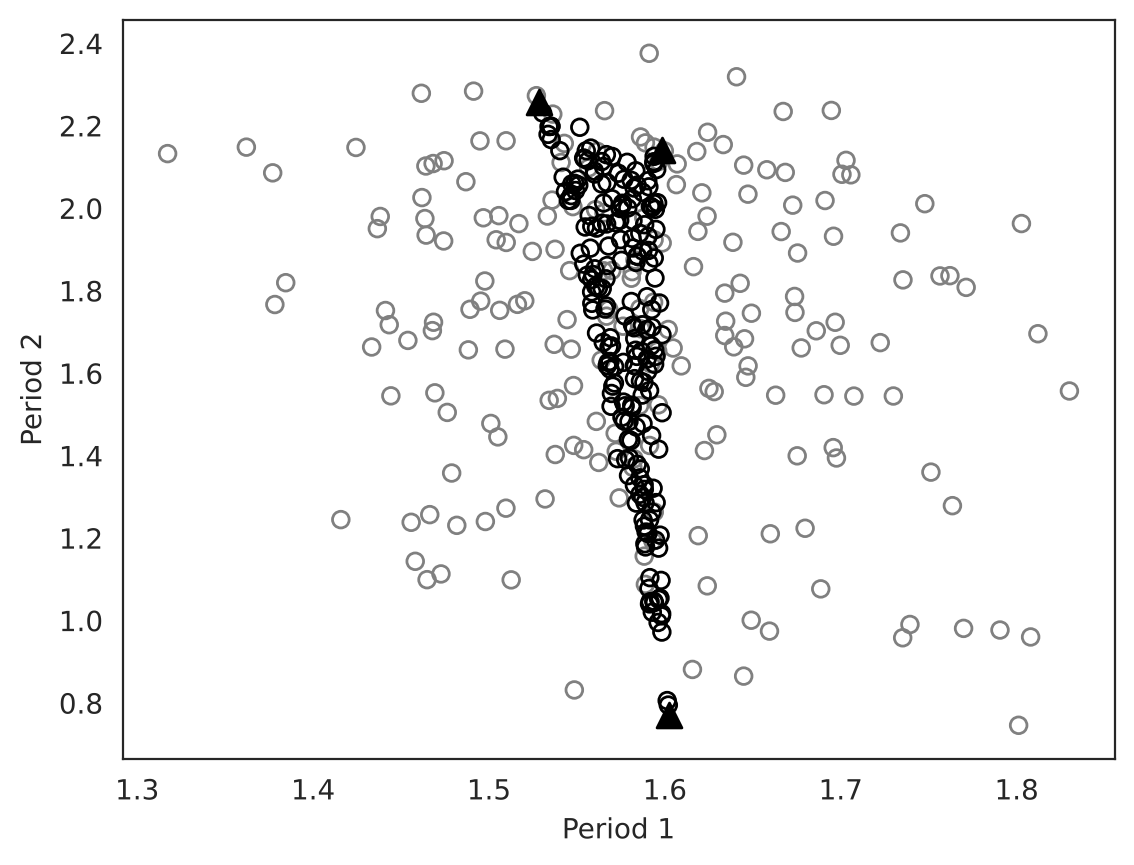

In [20]:
# observed outcomes (Ys) in grey
plt.scatter(Ys[0, :], Ys[1, :], facecolors='none', color='grey')

# average outcomes (Ybar) in black: the exact factor model
plt.scatter(Ybar[0, :], Ybar[1, :], facecolors='none', color='k')

# the factor vectors are the points of the triangle
plt.scatter(F[0, :], F[1, :], marker='^', color='k', s=80)

plt.xlabel('Period 1')
plt.ylabel('Period 2')
plt.show()

## 11.5.5 Convex Factor Model Estimator in Python

Step 1. Estimate the factor value matrix and the standard deviation of the error term.

In [21]:
from scipy import stats

def f_cmf(par, Y, K, Reps=10):
    """
    Convex factor model: minus the log likelihood
    * par: log of sigma, then the logs of the factor values
    * Y: outcomes, one row for each period and one column for each individual
    * K: number of factors
    * Reps: number of draws of the weights
    """
    eps = 1e-20
    # the seed is set inside the function, so the same weights
    # are drawn each time the function is called
    np.random.seed(123456789)
    T = Y.shape[0]
    N = Y.shape[1]
    sig = np.exp(par[0])
    # R fills a matrix column by column, order='F' does the same in numpy
    F = np.exp(par[1:(K*T+1)]).reshape((T, K), order='F')
    p = np.zeros((T, N))
    for r in range(0, Reps):
        # weights from a uniform distribution
        # which sum to 1 for each individual
        L = np.random.rand(K, N)
        L = L/L.sum(axis=0)
        # stats.norm.pdf is dnorm in R
        p = p + stats.norm.pdf((Y - F.dot(L))/sig)
    p = p/Reps
    # small number added because of logging in the next step.
    log_lik = -(np.mean(np.log(p + eps)) - np.log(sig))
    return log_lik

In [22]:
# we cheat and start from the true value of the standard deviation
# then 15 starting values for the factors (3 factors in 5 periods)
part = np.r_[np.log(0.1), np.random.normal(loc=0, scale=1, size=15)]

# estimated on the first five time periods only
a1 = minimize(f_cmf, part, args=(Ys[0:5, :], 3), method='Nelder-Mead',
              options={'maxiter': 1000000, 'initial_simplex': r_simplex(part)})
sighat = np.exp(a1.x[0])
print(sighat)

0.17715809182958422


In [23]:
Fhat = np.exp(a1.x[1:]).reshape((5, 3), order='F')

# estimated factor values (the true ones lie between 0 and 3)
pd.DataFrame(Fhat,
             index=['Period 1', 'Period 2', 'Period 3', 'Period 4', 'Period 5'],
             columns=['Factor 1', 'Factor 2', 'Factor 3'])

,Factor 1,Factor 2,Factor 3
Period 1,1.591456,1.583505,1.581620
Period 2,0.556992,2.609085,1.926508
Period 3,2.552255,0.001317,2.260518
Period 4,2.087522,2.116388,2.101395
Period 5,0.000053,0.015520,3.188743


Step 2. Estimate the weighting matrix.

In [24]:
def f_lambda(par, Y, F, sig):
    """
    Weights of one individual: minus the log likelihood
    * par: three numbers which give the weights
    * Y: outcomes of the individual
    * F, sig: factor values and standard deviation from step 1
    """
    eps = 1e-20
    # the weights are positive and sum to 1
    L = np.exp(par)/np.sum(np.exp(par))
    log_lik = -np.sum(np.log(stats.norm.pdf((Y - F.dot(L))/sig) + eps))
    return log_lik

The book draws the starting values below with a standard deviation of 20: the search then starts with almost all the weight on one factor, where the likelihood is flat, and the predictions of step 3 are the worst of the four methods. We use a standard deviation of 1, as the book does in section 11.6.4.

In [25]:
Lhat = np.zeros((3, 200))

for i in range(0, 200):
    parti = np.random.normal(loc=0, scale=1, size=3)
    ai = minimize(f_lambda, parti, args=(Ys[0:5, i], Fhat, sighat),
                  method='Nelder-Mead',
                  options={'initial_simplex': r_simplex(parti)})
    # one column of weights for each individual
    Lhat[:, i] = np.exp(ai.x)/np.sum(np.exp(ai.x))
    #print(i)

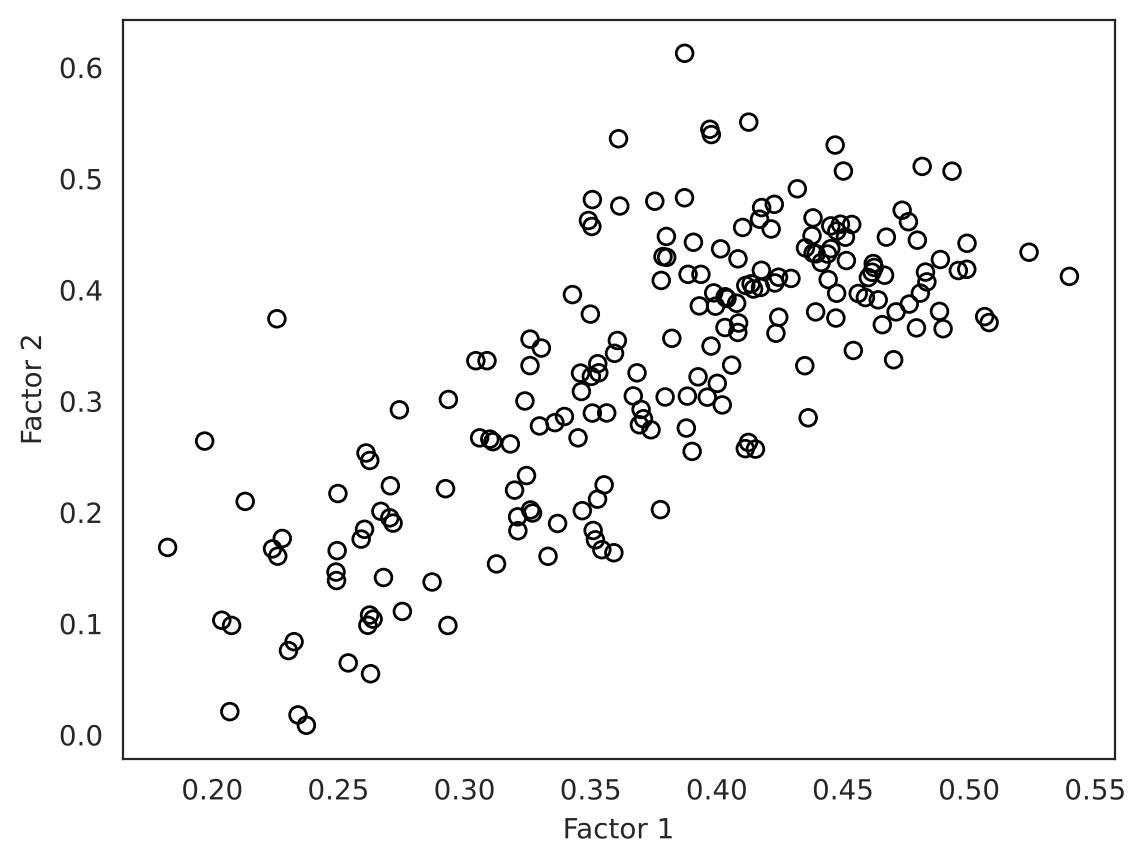

In [26]:
# plot of the estimated factor weights
plt.scatter(Lhat[0, :], Lhat[1, :], facecolors='none', color='k')
plt.xlabel('Factor 1')
plt.ylabel('Factor 2')
plt.show()

Step 3. Use the weights to predict the outcomes of individual 1.

In [27]:
# in python the inverse matrix can be found using
# the inv() function (from Numpy)
from numpy.linalg import inv

Ln1 = Lhat[:, 1:200]
L1 = Lhat[:, 0]
Yn1 = Ys[30:35, 1:200]
y1_hat_fm = Yn1.dot(Ln1.T).dot(inv(Ln1.dot(Ln1.T))).dot(L1)

In [28]:
# actual and predicted outcomes of individual 1 in periods 31 to 35
y1_act = Ys[30:35, 0]

tab_pred = pd.DataFrame({'Actual': y1_act,
                         'OLS': y1_hat_ols,
                         'SC': y1_hat_sc,
                         'LASSO': y1_hat_lasso,
                         'FM': y1_hat_fm},
                        index=[31, 32, 33, 34, 35])
tab_pred

,Actual,OLS,SC,LASSO,FM
31,0.801768,0.640767,1.020517,1.019629,0.891870
32,1.008653,1.216711,1.068928,1.117153,1.113310
33,1.953424,1.755821,2.025257,2.075436,2.089248
34,2.130891,1.837646,2.025235,2.059200,1.883502
35,1.030344,1.132339,1.134129,1.100834,1.100981


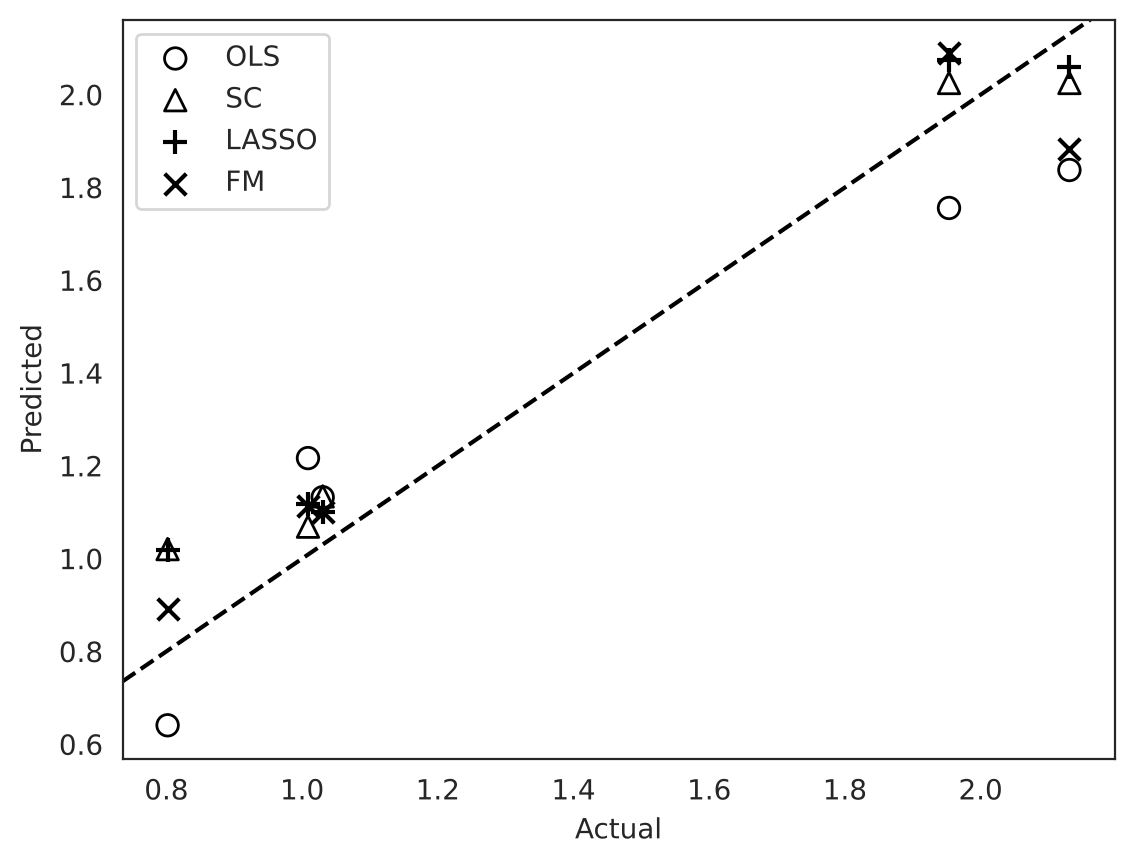

In [29]:
plt.scatter(y1_act, y1_hat_ols, marker='o', facecolors='none', color='k', s=60, label='OLS')
plt.scatter(y1_act, y1_hat_sc, marker='^', facecolors='none', color='k', s=60, label='SC')
plt.scatter(y1_act, y1_hat_lasso, marker='+', color='k', s=80, label='LASSO')
plt.scatter(y1_act, y1_hat_fm, marker='x', color='k', s=60, label='FM')

# the 45 degree line is perfect prediction
plt.axline((1, 1), slope=1, color='k', linestyle='--')

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.legend()
plt.show()

## 11.6.1 NLSY97 Data

In [30]:
# we take the data steps of chapter 10
x = pd.read_csv('../data/NLSY97Panel.csv')

# the file of names has no header: one name on each line
x_names = pd.read_csv('../data/NLSY97Panel_names.csv', header=None)
x.columns = list(x_names[0])

In [31]:
# create two matrices, with 18 (years)
# rows 8984 (individuals) columns
# one for income and one for hours worked.
year = list(range(1997, 2015))
year1 = ["97", "98", "99", "00", "01", "02", "03",
         "04", "05", "06", "07", "08",
         "09", "10", "11", "12", "13", "14"]
# below we need both versions of year.

# the matrices are full of NAs at the start
Y = np.full((18, 8984), np.nan)
W = np.full((18, 8984), np.nan)

for i in range(0, 18):
    # + is used to concatenate strings.
    hrs_name = "CVC_HOURS_WK_YR_ALL_" + year1[i] + "_XRND"
    inc_name = "YINC_1700_" + str(year[i])
    # "in" asks whether something is an element of a set.
    if hrs_name in x.columns:
        # negative numbers are codes for missing answers
        Y[i, :] = np.where(x[hrs_name] >= 0, x[hrs_name], np.nan)
    if inc_name in x.columns:
        W[i, :] = np.where(x[inc_name] >= 0, x[inc_name], np.nan)

In [32]:
def f_treat(W_07, Y_07):
    """
    Treatment variable, from income and hours worked in 2007
    * 1 if the person earns less than 7.26/hour or has no earnings in 2007
    * 0 if not
    * NA if we cannot tell
    """
    # calculates the wage rate for each person.
    rate_07 = W_07/Y_07
    treat = np.where((rate_07 < 7.26) | (W_07 == 0) | (Y_07 == 0), 1, 0)
    # in R a comparison with a missing value gives NA, in Python it gives False
    # so we put the NAs back when income or hours are missing
    missing = np.isnan(W_07) | np.isnan(Y_07)
    treat = np.where((treat == 0) & missing, np.nan, treat)
    return treat

# 2007 is the 11th year, so row 10 in Python
# this is x$treat in chapter 10
# the book uses it in section 11.6.4 under the name treat0, with no line to create it
treat0 = f_treat(W[10, :], Y[10, :])

In [33]:
def f_fe(Y, X=None, cross=True):
    """
    Fixed effects estimator of chapter 10
    * Y: outcomes, T rows (time periods) and N columns (individuals)
    * X: treatment, a matrix of the same size as Y
    * cross: True to add a dummy for each individual
    """
    T = Y.shape[0]
    N = Y.shape[1]
    # as.vector in R puts the columns of a matrix one under the other
    # .flatten(order='F') does the same in numpy
    df = pd.DataFrame({'y': Y.flatten(order='F')})
    # time period of each observation: 1 to T, for each individual
    df['t'] = np.tile(np.arange(1, T+1), N)
    if cross:  # create cross-section dummies
        # individual of each observation: each number T times
        df['c'] = np.repeat(np.arange(1, N+1), T)
    if X is not None:  # create treatment variable
        df['treat'] = X.flatten(order='F')
    # estimator
    # C() creates a dummy for each value, as as.factor() in R
    if cross and X is not None:  # standard case
        lm1 = sm.ols(formula="y ~ treat + C(t) + C(c)", data=df).fit()
    elif X is not None:  # no cross-section
        lm1 = sm.ols(formula="y ~ treat + C(t)", data=df).fit()
    else:  # no treatment
        lm1 = sm.ols(formula="y ~ C(t)", data=df).fit()
    return lm1

In [34]:
# using the same data as Chapter 10
N2 = 600  # restrict for computational reasons.
T2 = 18
Y2 = Y[:, 0:N2]
W2 = W[:, 0:N2]
treat1 = f_treat(W2[10, :], Y2[10, :])

# the treatment starts in 2007 (row 10)
treat = np.zeros((T2, N2))
for i in range(10, T2):
    treat[i, :] = treat1

# one individual has no observation left, so the dummy is a column of 0's
# R drops this dummy and says nothing, statsmodels gives a warning
# (statsmodels turns its warnings back on when it is imported,
# so we remove them again)
warnings.filterwarnings("ignore")

lm1 = f_fe(Y2, treat)
# fixed effects regression.

In [35]:
# the effect of the treatment, the same as in chapter 10 (-296.386)
print(lm1.params['treat'])

-296.38565150779414


In the book the second line for `Y_t` below reads `Y_t <- Y2[,is.na(colSums(Y_t))==0]`, which picks the columns among all the 600 individuals (three of the five it keeps are not treated). We pick them in `Y_t`.

In [36]:
# the residuals go back in a matrix with T2 rows and N2 columns
# statsmodels leaves out the rows with NAs
# lm1.resid.index gives the rows which are kept
# (in R lm1$na.action gives the rows which are left out)
res = np.full(T2*N2, np.nan)
res[lm1.resid.index] = lm1.resid
Y2 = res.reshape((T2, N2), order='F')

# split into treated and non-treated groups
# keep only those with data observed in all time-periods.
Y_t = Y2[:, treat1 == 1]
Y_t = Y_t[:, np.isnan(Y_t.sum(axis=0)) == False]
Y_t = Y_t[:, 0:5]  # restrict for computational reasons.
Y_nt = Y2[:, treat1 == 0]
Y_nt = Y_nt[:, np.isnan(Y_nt.sum(axis=0)) == False]

## 11.6.2 Synthetic Control Estimates of the Minimum Wage Effect

In [37]:
N_t = Y_t.shape[1]
N_nt = Y_nt.shape[1]
print(N_t, N_nt)

5 174


In [38]:
mat_treat = np.zeros((8, N_t))

for i in range(0, N_t):
    pari = np.random.normal(size=N_nt)
    # the weights are estimated on the 10 years before the treatment
    ai = minimize(f_sc, pari, args=(Y_t[0:10, i], Y_nt[0:10, :]),
                  method='Nelder-Mead',
                  options={'maxiter': 100000000,
                           'initial_simplex': r_simplex(pari)})
    omega = np.exp(ai.x)/np.sum(np.exp(ai.x))
    # actual outcome less synthetic control, in the 8 years of treatment
    mat_treat[:, i] = Y_t[10:18, i] - Y_nt[10:18, :].dot(omega)
    #print(i)

# add back in the results of the fixed effects.
mat_treat = mat_treat + lm1.params['treat']

# quantiles of results at 0.2, 0.5, and 0.8.
plot_res_sc = np.zeros((8, 3))
for i in range(0, 8):
    plot_res_sc[i, :] = np.nanquantile(mat_treat[i, :], [0.2, 0.5, 0.8])

## 11.6.3 LASSO Estimates of the Minimum Wage Effect

In [39]:
Y_tr = Y_t[0:8, :]  # training data
Y_tt = Y_t[8:10, :]  # test data
Y_ntr = Y_nt[0:8, :]
Y_ntt = Y_nt[8:10, :]

treat3 = np.zeros((8, N_t))

for i in range(0, N_t):
    omega = f_lasso(y_tr=Y_tr[:, i], y_tt=Y_tt[:, i],
                    Y_ntr=Y_ntr, Y_ntt=Y_ntt, K=10)
    treat3[:, i] = Y_t[10:18, i] - np.c_[np.ones(8), Y_nt[10:18, :]].dot(omega)
    #print(i)

treat3 = treat3 + lm1.params['treat']

plot_res_ls = np.zeros((8, 3))
for i in range(0, 8):
    plot_res_ls[i, :] = np.nanquantile(treat3[i, :], [0.2, 0.5, 0.8])

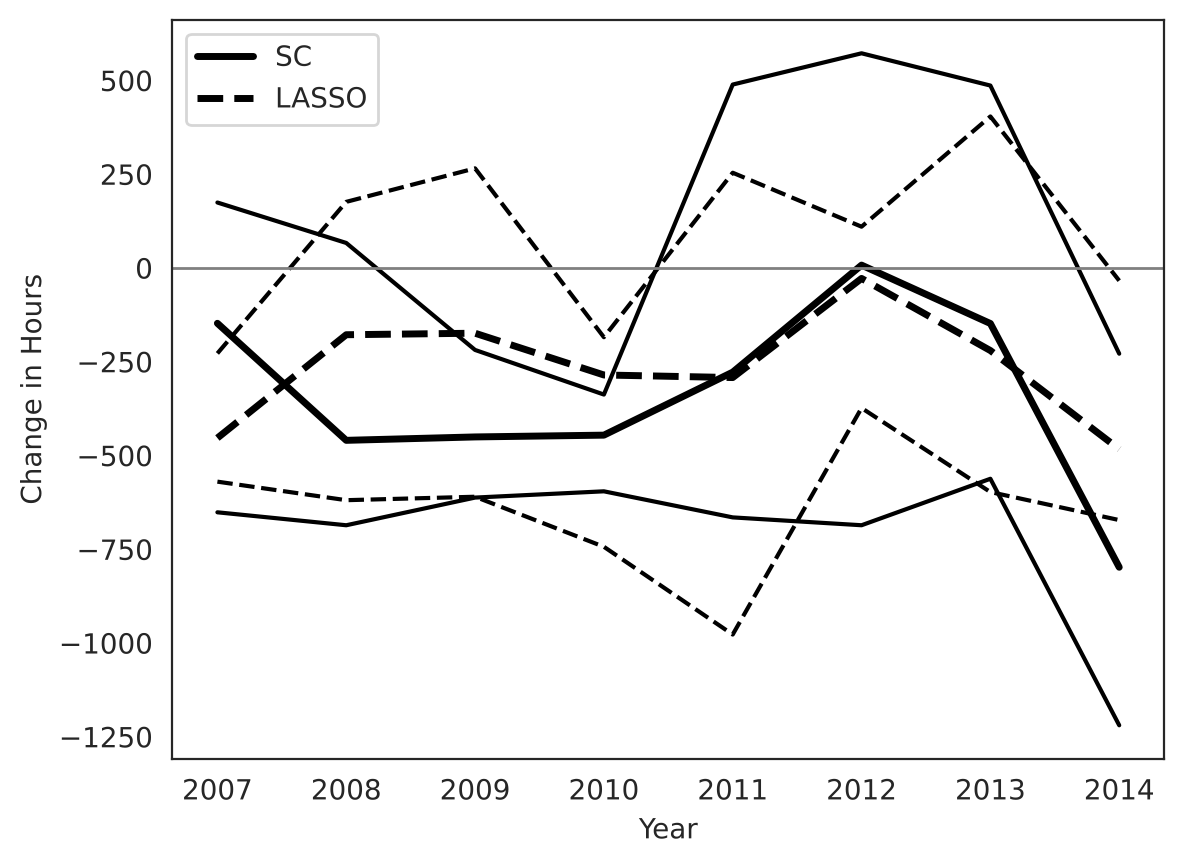

In [40]:
# the 8 years of treatment are 2007 to 2014
years = year[10:18]

# quantiles 20%, 50% and 80% of the effect on the five treated individuals
# thick line for the median
plt.plot(years, plot_res_sc[:, 1], color='k', linewidth=2.5, label='SC')
plt.plot(years, plot_res_sc[:, 0], color='k')
plt.plot(years, plot_res_sc[:, 2], color='k')
plt.plot(years, plot_res_ls[:, 1], color='k', linewidth=2.5, linestyle='--', label='LASSO')
plt.plot(years, plot_res_ls[:, 0], color='k', linestyle='--')
plt.plot(years, plot_res_ls[:, 2], color='k', linestyle='--')

# line at zero: no effect
plt.axhline(0, color='grey', linewidth=1)

plt.xlabel('Year')
plt.ylabel('Change in Hours')
plt.legend()
plt.show()

## 11.6.4 Factor Model Estimates of the Minimum Wage Effect

Step 0. Set the data up.

In [41]:
# the panel is aggregated up to half-decades:
# 1997 to 2001, 2002 to 2006 and 2007 to 2011
# np.nanmean with axis=0 is colMeans with na.rm = TRUE:
# the average of each column, leaving out the NAs
Y_1t = np.nanmean(Y[0:5, treat0 == 1], axis=0)
Y_2t = np.nanmean(Y[5:10, treat0 == 1], axis=0)
Y_3t = np.nanmean(Y[10:15, treat0 == 1], axis=0)
Y_1nt = np.nanmean(Y[0:5, treat0 == 0], axis=0)
Y_2nt = np.nanmean(Y[5:10, treat0 == 0], axis=0)
Y_3nt = np.nanmean(Y[10:15, treat0 == 0], axis=0)

# np.vstack puts the rows one under the other (rbind in R)
Y_t = np.vstack([Y_1t, Y_2t, Y_3t])
# keep the individuals observed in the three periods
index_t_na = np.isnan(Y_t.mean(axis=0)) == False
Y_t = Y_t[:, index_t_na]
Y_nt = np.vstack([Y_1nt, Y_2nt, Y_3nt])
Y_nt = Y_nt[:, np.isnan(Y_nt.mean(axis=0)) == False]

# treated first, then non-treated
Y_fm = np.c_[Y_t, Y_nt]
N_t = Y_t.shape[1]
N_nt = Y_nt.shape[1]
print(N_t, N_nt)

2163 3499


Step 1. Estimate the factor values and sigma in the pre-treatment period, with three factors.

The book draws the starting values of the factors with a standard deviation of 10, so a factor can start at exp(20) hours or more, where the likelihood is flat and sigma runs down to zero (the book has a footnote on this issue). We use a standard deviation of 1.

In [42]:
part = np.r_[np.log(400), np.random.normal(loc=0, scale=1, size=6)]

# the two pre-treatment periods, and 100 draws of the weights
a = minimize(f_cmf, part, args=(Y_fm[0:2, :], 3, 100), method='Nelder-Mead',
             options={'maxiter': 1000000, 'initial_simplex': r_simplex(part)})
# sigma
sighat = np.exp(a.x[0])
print(sighat)

406.585885899952


In [43]:
Fhat = np.exp(a.x[1:]).reshape((2, 3), order='F')

# estimated factor values, in hours per year
pd.DataFrame(Fhat.round(2),
             index=['1997 to 2001', '2002 to 2006'],
             columns=['Factor 1', 'Factor 2', 'Factor 3'])

,Factor 1,Factor 2,Factor 3
1997 to 2001,0.67,1745.12,0.04
2002 to 2006,0.70,0.00,4030.61


Step 2. Determine the weights.

In [44]:
Lhat = np.zeros((3, Y_fm.shape[1]))
np.random.seed(123456789)

for i in range(0, Y_fm.shape[1]):
    parti = np.random.normal(loc=0, scale=1, size=3)
    ai = minimize(f_lambda, parti, args=(Y_fm[0:2, i], Fhat, sighat),
                  method='Nelder-Mead',
                  options={'initial_simplex': r_simplex(parti)})
    Lhat[:, i] = np.exp(ai.x)/np.sum(np.exp(ai.x))
    #print(i)

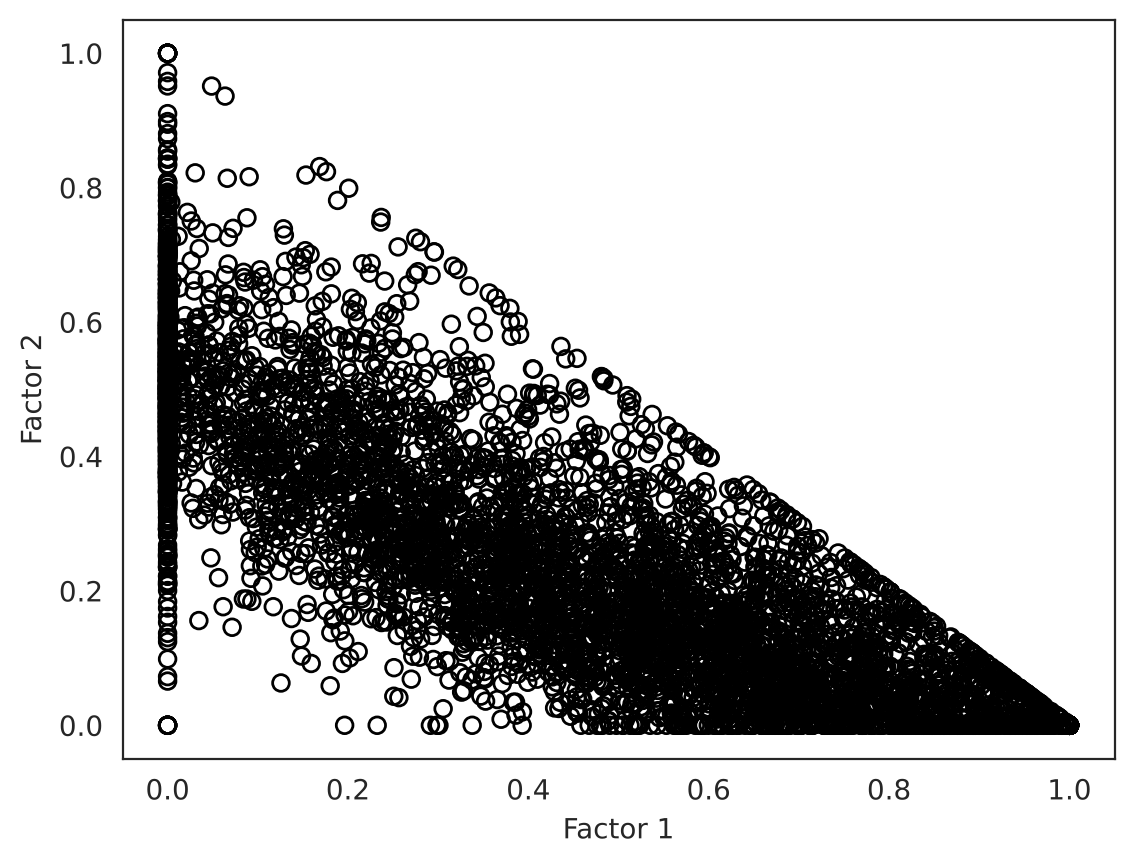

In [45]:
# plot of the weights of the 5662 individuals
plt.scatter(Lhat[0, :], Lhat[1, :], facecolors='none', color='k')
plt.xlabel('Factor 1')
plt.ylabel('Factor 2')
plt.show()

Step 3. Use the weights to build the synthetic control of each treated individual.

In [46]:
# the treated are the first N_t columns
Lhat_t = Lhat[:, 0:N_t]
Lhat_nt = Lhat[:, N_t:]

# one column of weights on the non-treated for each treated individual
Omega = Lhat_nt.T.dot(inv(Lhat_nt.dot(Lhat_nt.T))).dot(Lhat_t)

# actual hours less synthetic control in the third period (2007 to 2011)
itt = Y_t[2, :] - Y_nt[2, :].dot(Omega)

# .describe() is summary() in R
pd.Series(itt).describe().round(1)

count    2163.0
mean     -527.7
std       840.4
min     -2317.7
25%     -1260.8
50%      -643.2
75%       125.1
max      3371.0
dtype: float64

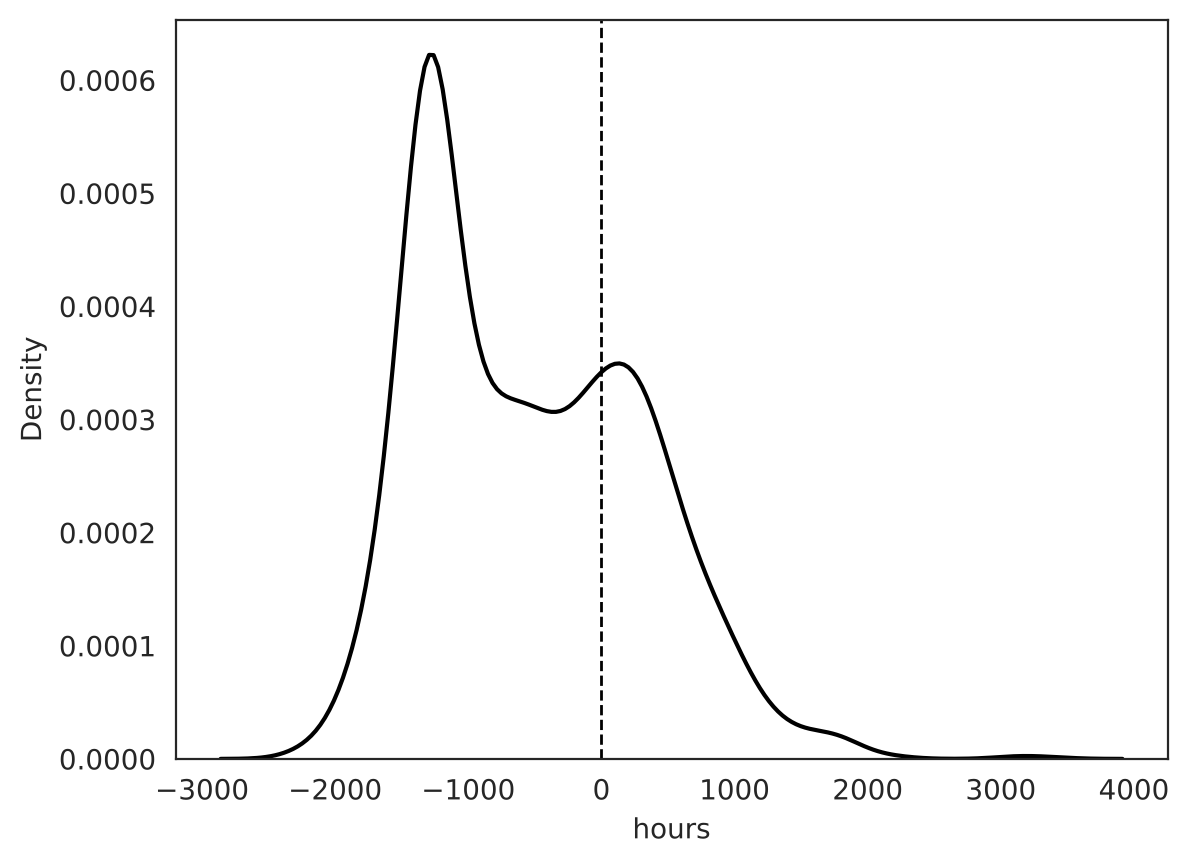

In [47]:
# density of the individual treatment effect for the treated
sns.kdeplot(itt, color='k')
plt.axvline(0, color='k', linestyle='--', linewidth=1)
plt.xlabel('hours')
plt.show()

In [48]:
# average income of the treated in periods 2 and 3
W_2t = np.nanmean(W[5:10, treat0 == 1], axis=0)
W_2t = W_2t[index_t_na]
W_3t = np.nanmean(W[10:15, treat0 == 1], axis=0)
W_3t = W_3t[index_t_na]

# actual income in period 3 less counter-factual income
# (hours times the wage rate of period 2)
inc = W_3t - (Y_3t[index_t_na] + itt)*W_2t/Y_2t[index_t_na]

# leave out the NAs and the infinite values (no hours in period 2)
inc = inc[(np.isnan(inc) == False) & (np.isinf(inc) == False)]
pd.Series(inc).describe().round(0)

count        1464.0
mean        55351.0
std       1397069.0
min      -4416355.0
25%          1756.0
50%          7624.0
75%         15765.0
max      52975002.0
dtype: float64

In the line above the book takes `Y_3t + itt` for the hours without the minimum wage increase, but `itt` is actual hours less these hours, so they are `Y_3t - itt`. With this sign:

In [49]:
inc2 = W_3t - (Y_3t[index_t_na] - itt)*W_2t/Y_2t[index_t_na]
inc2 = inc2[(np.isnan(inc2) == False) & (np.isinf(inc2) == False)]
pd.Series(inc2).describe().round(0)

count        1464.0
mean       -49575.0
std       1390199.0
min     -52850002.0
25%         -4837.0
50%          2595.0
75%         10882.0
max         84656.0
dtype: float64